<a href="https://colab.research.google.com/github/Mufliha-Hafsyah/244107020147-mobile-course/blob/main/Week03/Week3_14.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **LAPORAN PRAKTIKUM <br> Pengolahan Citra dan Visi Komputer (PCVK)**

**Nama** : Mufliha Hafsyah Shahieza <br>
**NIM** : 244107020147 <br>
**Kelas** : TI-3G

---

## **Modul 3 – Operasi Citra Sederhana**

In [ ]:
# ===== SEL IDENTITAS - JANGAN DIHAPUS, HARUS SEL PERTAMA =====
import sys, platform, hashlib, datetime, zoneinfo

NAMA = 'Mufliha Hafsyah Shahieza'
NIM = '244107020147'

N = int(NIM[-3:])
PARAM = {
    'b'     : (N % 61) + 20,
    'a'     : round(1.0 + (N % 9) / 10, 1),
    'c'     : (N % 20) + 30,
    'gamma' : round(0.4 + (N % 6) * 0.25, 2),
    'bit'   : (N % 6) + 2,
}
waktu = datetime.datetime.now(zoneinfo.ZoneInfo('Asia/Jakarta'))

print('NAMA   :', NAMA)
print('NIM    :', NIM, '| N =', N)
for k, v in PARAM.items():
    print('%-6s :' % k, v)
print('WAKTU  :', waktu.strftime('%Y-%m-%d %H:%M:%S %Z'))
print('SISTEM :', sys.version.split()[0], platform.platform())
kunci = NIM + '|' + waktu.strftime('%Y-%m-%d')
print('TOKEN  :', hashlib.sha256(kunci.encode()).hexdigest()[:16])

NAMA   : Mufliha Hafsyah Shahieza
NIM    : 244107020147 | N = 147
b      : 45
a      : 1.3
c      : 37
gamma  : 1.15
bit    : 5
WAKTU  : 2026-09-18 17:24:40 WIB
SISTEM : 3.13.15 Linux-6.6.122+-x86_64-with-glibc2.39
TOKEN  : df6c624e10fa550f


### **E1. Operasi Citra Sederhana**

1. **Akses folder images pada Google Drive:**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


2. **Melakukan transformasi linier brightness dengan memasukkan nilai konstanta tertentu
dan menghasilkan warna**

**Transformasi Linier Brightness**<br>
Formula: *g(x,y) = f(x,y)+b*<br>
* *g(x,y)* adalah nilai pixel setelah transformasi
* *f(x,y)* adalah nilai piksel asli
* *b* adalah nilai brightness

 Mengubah tingkat kecerahan citra 
----------------------------------
Masukkan nilai kecerahan: 45


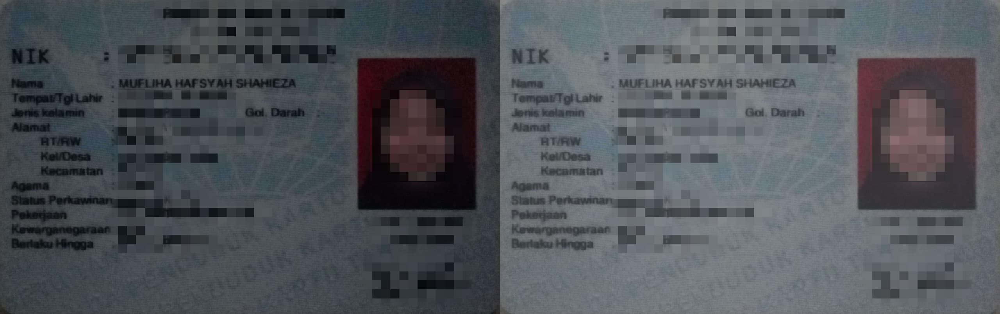

In [ ]:
import cv2 as cv
from google.colab.patches import cv2_imshow
from skimage import io
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

print(' Mengubah tingkat kecerahan citra ')
print('----------------------------------')
try:
  brightness = int(input('Masukkan nilai kecerahan: '))
except ValueError:
  print('Error, not a number')

original = cv.imread('/content/drive/MyDrive/PCVK2026/KTP1a.jpeg')
brightness_image = np.zeros(original.shape, original.dtype)

#akses per piksel
#np.clip digunakan untuk melakukan truncate pixel (nilai dibatasi antara 0-255)
for y in range(original.shape[0]):
  for x in range(original.shape[1]):
    for c in range(original.shape[2]):
      brightness_image[y,x,c] = np.clip(original[y,x,c] + brightness, 0, 255)

#cara simple tanpa for loop
#brightness_img = cv.convertScaleAbs(original, beta=brightness)

final_frame = cv.hconcat((original, brightness_image))
cv2_imshow(final_frame)

### **TUGAS PRAKTIKUM**

1. **Implementasikan inverse citra pada Google Colaboratory menggunakan formula pada
bagian Ulasan Teori. Terapkan pada KTM1b.jpg dan KTM1a.jpg, tampilkan
berdampingan dengan citra aslinya. Jelaskan mengapa citra negatif dari KTM1a
(ruangan gelap) tampak pucat dan berkabut, sedangkan negatif dari KTM1b tetap
kontras.**



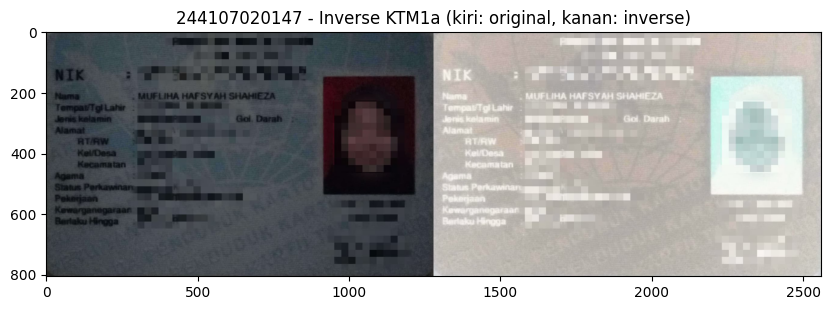

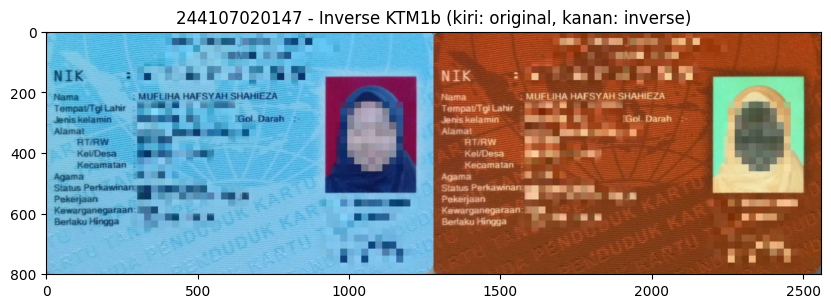

In [ ]:
KTP1a = cv.imread('/content/drive/MyDrive/PCVK2026/KTP1a.jpeg')
KTP1b = cv.imread('/content/drive/MyDrive/PCVK2026/KTP1b.jpeg')

inv_KTP1a = 255 - KTP1a
inv_KTP1b = 255 - KTP1b

# KTP1a: original vs inverse
final_frame_a = cv.hconcat((KTP1a, inv_KTP1a))
plt.figure(figsize=(10,5))
plt.imshow(cv.cvtColor(final_frame_a, cv.COLOR_BGR2RGB))
plt.title(NIM + ' - Inverse KTM1a (kiri: original, kanan: inverse)')
plt.show()

# KTP1b: original vs inverse
final_frame_b = cv.hconcat((KTP1b, inv_KTP1b))
plt.figure(figsize=(10,5))
plt.imshow(cv.cvtColor(final_frame_b, cv.COLOR_BGR2RGB))
plt.title(NIM + ' - Inverse KTM1b (kiri: original, kanan: inverse)')
plt.show()

Jelaskan mengapa citra negatif dari KTM1a (ruangan gelap) tampak pucat dan berkabut, sedangkan negatif dari KTM1b tetap kontras. <br>
**Jawaban:** <br>
* KTM1a diambil di ruangan gelap, sehingga nilai piksel aslinnya berkumpul di angka rendah (mendekati 0). Saat di-inverse nilai-nilai piksel rendah yang berdekatan tersebut sama-sama berubah menjadi nilai tinggi (mendekati 255) dan saling berdekatan pula. Akibatnya, citra hasil negatif didominasi warna terang yang seragam, sehingga tampak pucat dan berkabut.
* Sebaliknya, KTM1b diambil dengan pencahayaan lampu ruangan yang cukup, sehingga rentang nilai piksel aslinya sudah bervariasi lebar. Saat di-inverse, variasi lebar ini tetap terjaga (piksel gelap dan terang hanya saling bertukar posisi nilai, bukan menyempit ke satu rentang), sehingga detail dan kontras pada citra negatifnya tetap terlihat jelas.

Jadi, dapat diambil kesimpulan bahwa kualitas kontras citra negatif sangat bergantung pada range nilai piksel citra asli. Semakin sempit rentang nilai piksel asli, semakin pucat/berkabut hasil inverse-nya. Semakin lebar rentang nilai piksel asli, semakin kontras pula hasil inverse-nya.

2. **Implementasikan transformasi kontras dengan nilai a yang dihitung dari NIM Anda
(PARAM['a']) pada KTM1a.jpg**

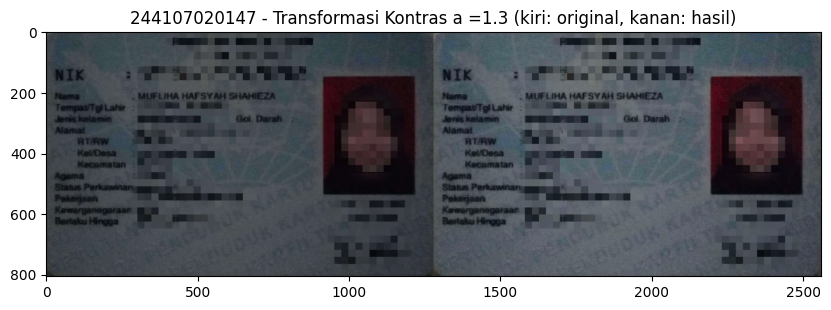

In [ ]:
KTP1a = cv.imread('/content/drive/MyDrive/PCVK2026/KTP1a.jpeg')

a = PARAM['a']
kontras = np.clip(KTP1a.astype(np.float32) * a, 0, 255).astype(np.uint8)

final_frame_kontras = cv.hconcat((KTP1a, kontras))

plt.figure(figsize=(10,5))
plt.imshow(cv.cvtColor(final_frame_kontras, cv.COLOR_BGR2RGB))
plt.title(NIM + ' - Transformasi Kontras a =' + str(a) + ' (kiri: original, kanan: hasil)')
plt.show()

3. **Implementasikan transformasi logarithmic brightness dengan konstanta c hasil hitung
dari NIM (PARAM['c']) pada KTM1a.jpg. Bandingkan hasilnya dengan linier brightness
memakai nilai b hasil hitung dari NIM (PARAM['b']) pada citra yang sama. Tentukan
metode mana yang membuat NIM pada kartu Anda lebih terbaca, dan tunjukkan
bagian mana yang menjadi putih penuh (clipping) pada masing-masing metode.**

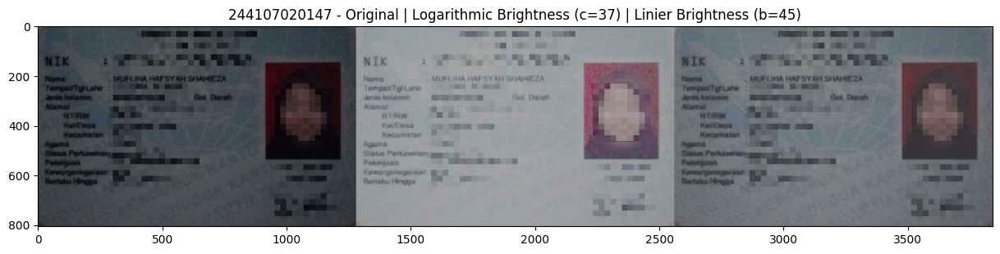

In [ ]:
from os import link
KTP1a = cv.imread('/content/drive/MyDrive/PCVK2026/KTP1a.jpeg')

c = PARAM['c']
b = PARAM['b']

# Logarithmic Brightness
log_KTP1a = c * np.log(1 + KTP1a.astype(np.float32))
log_KTP1a = np.clip(log_KTP1a, 0, 255).astype(np.uint8)

# Linier Brightness
lin_KTP1a = np.clip(KTP1a.astype(np.int16) + b, 0, 255).astype(np.uint8)

final_frame = cv.hconcat((KTP1a, log_KTP1a, lin_KTP1a))

plt.figure(figsize=(15,5))
plt.imshow(cv.cvtColor(final_frame, cv.COLOR_BGR2RGB))
plt.title(NIM + ' - Original | Logarithmic Brightness (c=' + str(c) + ') | Linier Brightness (b=' + str(b) + ')')
plt.show()


**Jawaban:** <br>
* Berdasarkan hasil eksperimen pada KTM1a.jpg, ternyata metode Linier Brightness (b=45) menghasilkan citra yang lebih terbaca dibanding Logarithmic Brightness (c=37), berbeda dengan teori umum yang biasanya menyebutkan Log Brightness lebih unggul untuk citra gelap.

* Hal ini terjadi karena nilai c=37 dengan basis logaritma natural (np.log) menghasilkan rentang keluaran maksimum hanya sekitar 205 (37 × ln(256) ≈ 205,2), sehingga seluruh piksel "dipadatkan" ke rentang sempit dan justru terlihat pudar, meskipun secara teknis tidak ada piksel yang mengalami clipping ke 255.

* Sebaliknya, Linier Brightness menambahkan nilai konstan +45 secara merata sehingga proporsi kontras relatif antar piksel pada citra asli tetap terjaga.

* Pada kedua citra hasil transformasi, tidak ditemukan bagian yang benar-benar putih (nilai piksel 255). Pada Logarithmic Brightness hal ini wajar terjadi karena nilai output maksimumnya secara matematis memang tidak bisa mencapai 255, dibuktikan dari perhitungan (37 × ln(256) ≈ 205), sehingga sebesar apapun nilai piksel aslinya, hasilnya tidak akan pernah mentok di 255. <br>Sedangkan pada Linier Brightness, tidak ada bagian yang di clipping artinya nilai piksel paling terang pada citra asli KTM1a masih berada di bawah 210 (255−45 = 210), sehingga penambahan konstanta +45 belum sampai membuat piksel manapun melewati batas 255.




4. **Implementasikan transformasi grayscale metode averaging, lightness, dan luminance
pada KTM1c.jpg, yaitu citra yang diambil dengan flash. Hitung rata-rata dan
simpangan baku intensitas hasil ketiga metode, sajikan dalam satu tabel, lalu tentukan
metode mana yang memberi pemisahan paling jelas antara teks dan latar kartu.**<br><br>
Rumus:
* Averaging: (R + G + B) / 3
* Lightness: (max(R,G,B) + min(R,G,B)) / 2
* Luminance: 0,299R + 0,587G + 0,114B

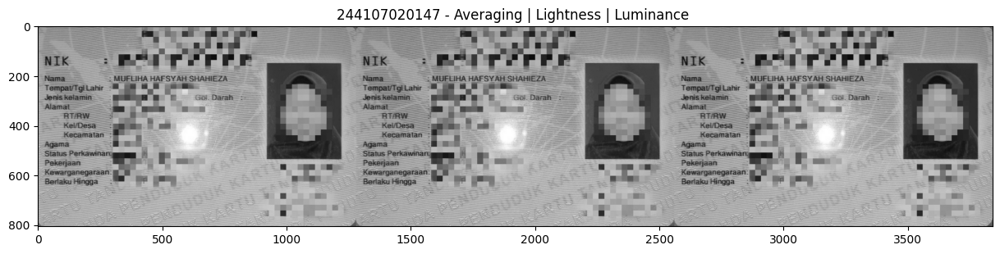

      Metode   Rata-rata  Simpangan Baku
0  Averaging  149.567586       46.193283
1  Lightness  146.679814       44.384975
2  Luminance  147.573296       47.415587


In [ ]:
KTP1c = cv.imread('/content/drive/MyDrive/PCVK2026/KTP1c.jpeg')
KTP1c_f = KTP1c.astype(np.float32)

B = KTP1c_f[:,:,0]
G = KTP1c_f[:,:,1]
R = KTP1c_f[:,:,2]

# Averaging
gray_avg = ((R + G + B) / 3).astype(np.uint8)

# Lightness
gray_light = ((np.maximum(np.maximum(R,G),B) + np.minimum(np.minimum(R,G),B)) / 2).astype(np.uint8)

# Luminance (Rec. 601, sama seperti cv.COLOR_BGR2GRAY)
gray_lum = (0.299*R + 0.587*G + 0.114*B).astype(np.uint8)

final_frame = cv.hconcat((gray_avg, gray_light, gray_lum))

plt.figure(figsize=(15,5))
plt.imshow(final_frame, cmap='gray')
plt.title(NIM + ' - Averaging | Lightness | Luminance ')
plt.show()

# Hitung rata-rata dan simpangan baku
data = {
    'Metode': ['Averaging', 'Lightness', 'Luminance'],
    'Rata-rata': [np.mean(gray_avg), np.mean(gray_light), np.mean(gray_lum)],
    'Simpangan Baku': [np.std(gray_avg), np.std(gray_light), np.std(gray_lum)]
}
df = pd.DataFrame(data)
print(df)

**Jawaban:** <br>
Ketiga metode grayscaling diterapkan pada KTP1c.jpg menghasilkan rata-rata dan simpangan baku sebagai berikut:

| Metode | Rata-rata | Simpangan Baku |
|---|---|---|
| Averaging | 149.57 | 46.19 |
| Lightness | 146.68 | 44.38 |
| Luminance | 147.57 | 47.42 |

* Simpangan baku merepresentasikan seberapa lebar sebaran intensitas piksel pada citra. Semakin besar nilainya, semakin lebar rentang gelap-terangnya, sehingga pemisahan antara teks (gelap) dan background kartu (terang) semakin jelas.
* Metode Luminance memiliki simpangan baku tertinggi (47.42), sedikit di atas Averaging (46.19) dan Lightness (44.38). Hal ini terjadi karena Luminance memberi bobot lebih besar pada channel Green (0.587) yang paling dominan berkontribusi terhadap persepsi kecerahan mata manusia, sehingga kontras antara teks gelap dan background terang lebih terangkat dibanding metode lain yang memperlakukan ketiga channel secara lebih merata (Averaging) atau hanya berdasarkan nilai ekstrem max-min (Lightness).

Jadi, dapat diambil kesimpulan bahwa metode Luminance memberikan pemisahan paling jelas antara teks dan background kartu pada KTP1c.jpg, karena pembobotan channelnya lebih merepresentasikan persepsi kontras visual dibanding Averaging maupun Lightness.

5. **Tampilkan satu warna tertentu pada citra dan ubah bagian lainnya menjadi grayscale.
Gunakan OBJ1.jpg, yaitu foto benda milik Anda sendiri dengan satu warna dominan.
Sebutkan rentang nilai HSV yang Anda pakai sebagai batas warna, lalu tunjukkan
pengaruhnya apabila rentang tersebut diperlebar dan dipersempit.**

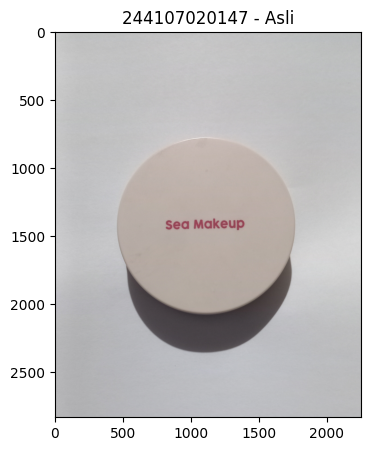

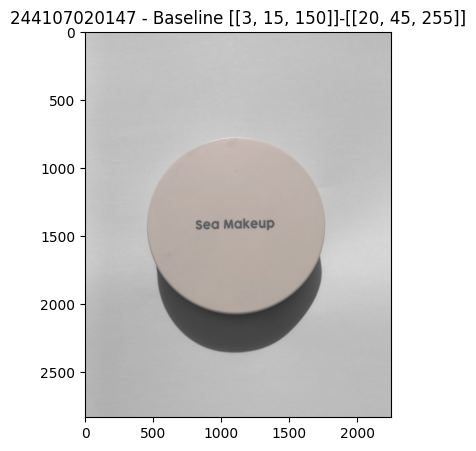

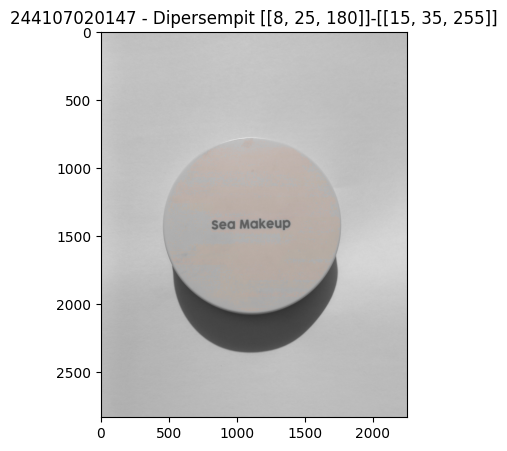

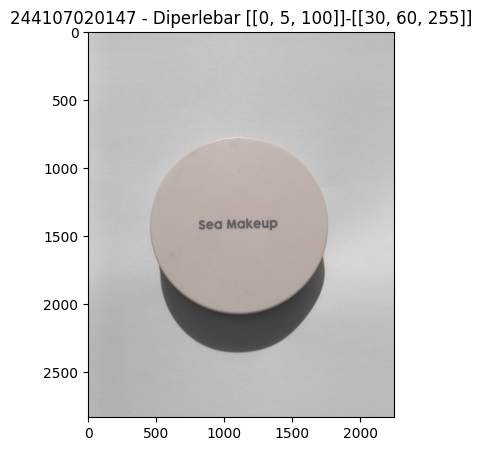

In [ ]:
OBJ1 = cv.imread('/content/drive/MyDrive/PCVK2026/OBJ1.jpg')
hsv = cv.cvtColor(OBJ1, cv.COLOR_BGR2HSV)
gray = cv.cvtColor(OBJ1, cv.COLOR_BGR2GRAY)
gray_3ch = cv.cvtColor(gray, cv.COLOR_GRAY2BGR)

#citra asli
plt.figure(figsize=(6,5))
plt.imshow(cv.cvtColor(OBJ1, cv.COLOR_BGR2RGB))
plt.title(NIM + ' - Asli')
plt.show()

#baseline
lower = np.array([3, 15, 150])
upper = np.array([20, 45, 255])
mask = cv.inRange(hsv, lower, upper)
result = np.where(mask[:, :, None].astype(bool), OBJ1, gray_3ch)

plt.figure(figsize=(6,5))
plt.imshow(cv.cvtColor(result, cv.COLOR_BGR2RGB))
plt.title(NIM + f' - Baseline [{lower.tolist()}]-[{upper.tolist()}]')
plt.show()

#rentang dipersempit
lower = np.array([8, 25, 180])
upper = np.array([15, 35, 255])
mask = cv.inRange(hsv, lower, upper)
result = np.where(mask[:, :, None].astype(bool), OBJ1, gray_3ch)

plt.figure(figsize=(6,5))
plt.imshow(cv.cvtColor(result, cv.COLOR_BGR2RGB))
plt.title(NIM + f' - Dipersempit [{lower.tolist()}]-[{upper.tolist()}]')
plt.show()

#rentang diperlebar
lower = np.array([0, 5, 100])
upper = np.array([30, 60, 255])
mask = cv.inRange(hsv, lower, upper)
result = np.where(mask[:, :, None].astype(bool), OBJ1, gray_3ch)

plt.figure(figsize=(6,5))
plt.imshow(cv.cvtColor(result, cv.COLOR_BGR2RGB))
plt.title(NIM + f' - Diperlebar [{lower.tolist()}]-[{upper.tolist()}]')
plt.show()


* Rentang HSV baseline yang dipakai untuk mempertahankan warna dominan objek adalah H: 3–20, S: 15–45, V: 150–255. Nilai ini ditentukan dengan mengamati sebaran warna dominan citra di ruang HSV untuk mencakup area objek tanpa terbawa ke background.

* Penentuan rentang dilakukan secara trial-and-error menguji fungsi cv.inRange() hingga diperoleh hasil masking yang paling presisi (objek tertutup utuh, background bersih).

* Dampak rentang diperlebar yaitu meningkatkan coverage sehingga area objek tertutup solid tanpa bolong, namun menurunkan presisi karena rawan memicu noise/false positive dari background.

* Dampak rentang dipersempit yaitu meningkatkan presisi warna, tetapi menurunkan coverage sehingga area objek bertumpuk bayangan/gradasi mudah terlewat dan memicu efek bolong-bolong.





6. **Gamma Correction pada Citra Pribadi
Nilai gamma diminta dari pengguna melalui kode di bawah ini. Lanjutkan kode tersebut
sesuai rumus pada Ulasan Teori, kemudian terapkan pada KTM1a.jpg. Mulailah dari nilai
gamma hasil hitung dari NIM Anda, lalu cari secara bertahap nilai gamma yang membuat
NIM dan nama pada kartu paling terbaca. Tampilkan minimal lima nilai gamma yang dicoba beserta hasilnya, sebutkan nilai gamma terbaik pilihan Anda, dan jelaskan
mengapa nilai terbaik setiap mahasiswa berbeda meskipun jenis objeknya sama.**

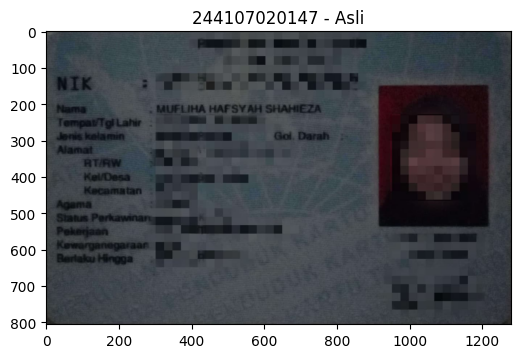

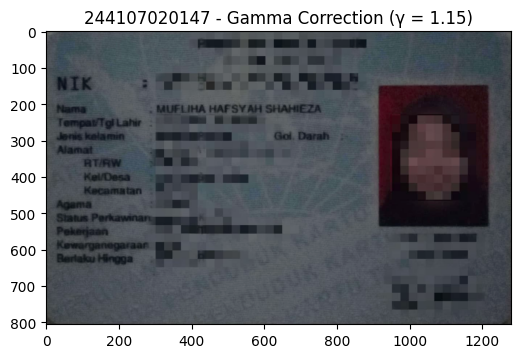

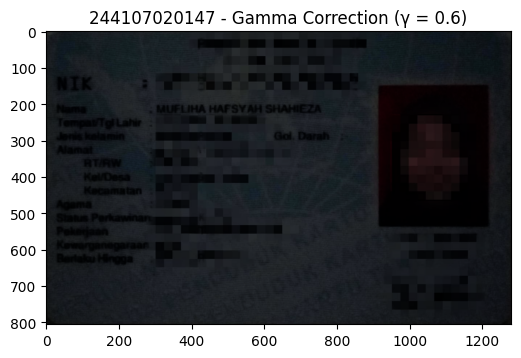

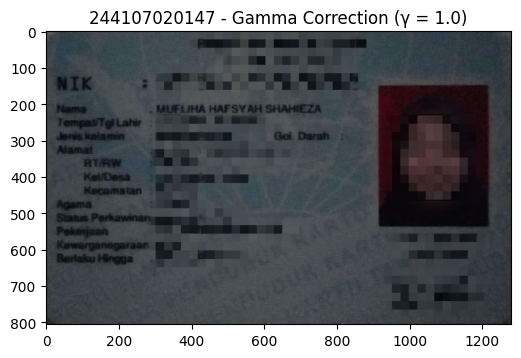

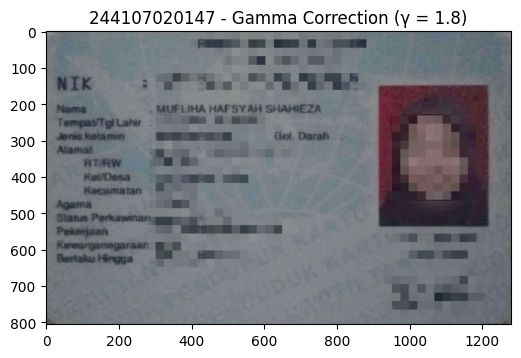

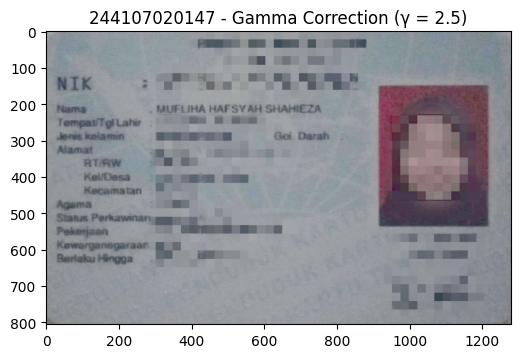

In [ ]:
KTP1a = cv.imread('/content/drive/MyDrive/PCVK2026/KTP1a.jpeg')

def gamma_correction(img, gamma):
    normalized = img.astype(np.float64) / 255.0
    corrected = np.power(normalized, 1.0 / gamma)
    result = np.clip(corrected * 255.0, 0, 255).astype(np.uint8)
    return result

# tampilkan citra asli
plt.figure(figsize=(6,5))
plt.imshow(cv.cvtColor(KTP1a, cv.COLOR_BGR2RGB))
plt.title(NIM + ' - Asli')
plt.show()

# daftar nilai gamma yang dicoba, mulai dari PARAM['gamma']
gamma_list = [PARAM['gamma'], 0.6, 1.0, 1.8, 2.5]

for g in gamma_list:
    result = gamma_correction(KTP1a, g)
    plt.figure(figsize=(6,5))
    plt.imshow(cv.cvtColor(result, cv.COLOR_BGR2RGB))
    plt.title(NIM + f' - Gamma Correction (γ = {g})')
    plt.show()

**Jawaban:**<br>
Dari lima nilai gamma yang diuji coba (0.6, 1.0, 1.15, 1.8, 2.5), nilai γ = 1.15 dipilih sebagai nilai terbaik karena memberikan keterbacaan teks Nama yang paling jelas tanpa menimbulkan efek clipping seperti yang terjadi pada γ = 2.5, maupun efek terlalu gelap seperti pada γ = 0.6.
<br>

**Mengapa nilai terbaik setiap mahasiswa berbeda meskipun jenis objeknya sama?**<br>
Alasannya karena:
* Setiap mahasiswa memotret KTP/KTM masing-masing dengan kondisi pencahayaan dan kamera yang berbeda, sehingga level kecerahan awal (histogram) citra asli juga berbeda.
* Nilai PARAM['gamma'] sendiri diturunkan dari NIM masing-masing, jadi titik awal eksplorasi berbeda-beda per orang.
* Karena histogram awal berbeda, jumlah koreksi yang dibutuhkan agar teks terbaca optimal juga otomatis berbeda, citra yang lebih gelap dari awal butuh gamma < 1 lebih kecil dibanding citra yang sudah cukup terang.

7. **Buat Simulasi Image Depth pada Citra Pribadi <br>
Percobaan ini digunakan sebagai simulasi dari proses kuantisasi citra. Pada kuantisasi
citra, pixel dapat direpresentasikan dengan n-bit kedalaman (default menggunakan 8-bit).
Pada pixel 8-bit, warna yang memungkinkan adalah 256 warna, dari 0 (0000 0000) hingga
255(1111 1111). Pada pixel 7-bit, warna yang memungkinkan adalah 128 warna, dari 0
(000 0000) hingga 127 (111 1111). Kemungkinan warna didapat dari pangkat 2 jumlah bit.
Jika 7bit, maka jumlah warnanya adalah 2^7 = 128, dst.<br><br>
Kuantisasi KTM1b.jpg pada kedalaman 1 sampai 7 bit dan tampilkan seluruh hasilnya.
Tentukan pada kedalaman berapa nama dan NIM pada kartu Anda masih terbaca**

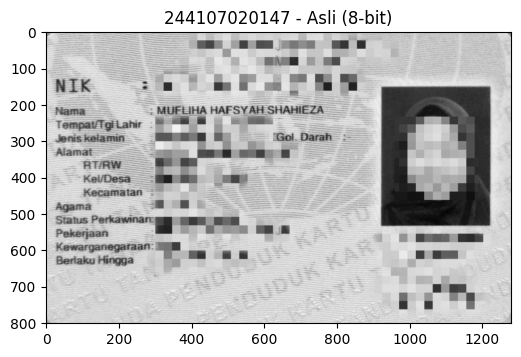

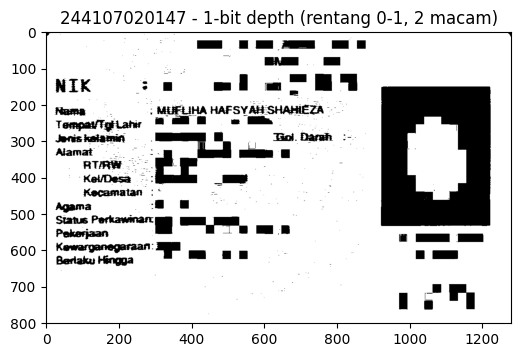

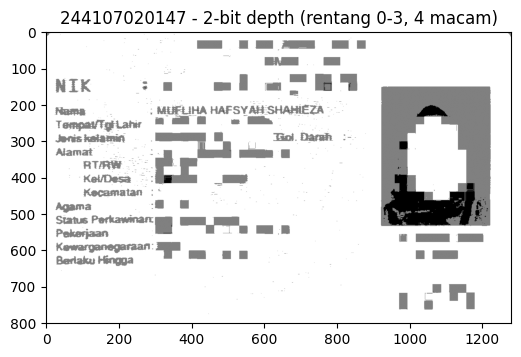

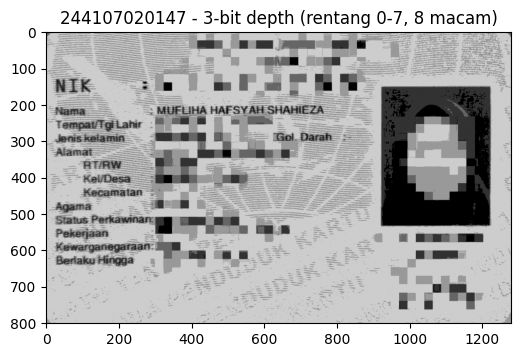

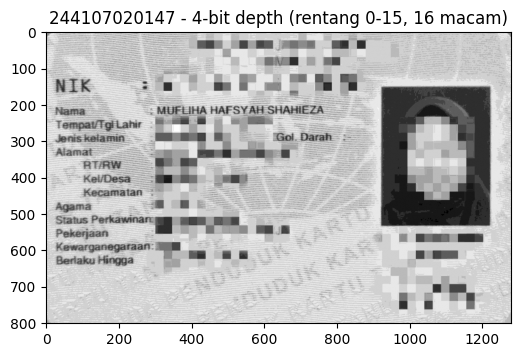

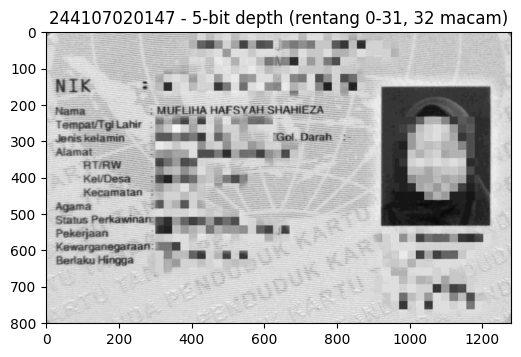

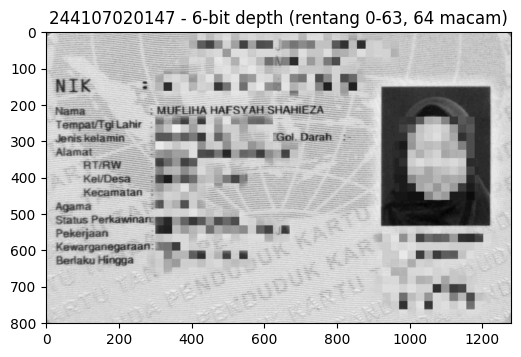

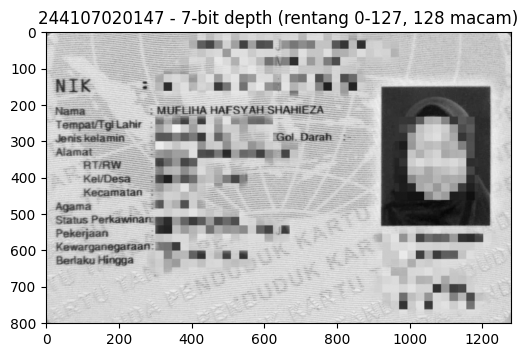

In [ ]:
KTM1b_gray = cv.imread('/content/drive/MyDrive/PCVK2026/KTP1b.jpeg', cv.IMREAD_GRAYSCALE)

def simulate_bit_depth(img, bit_depth):
    level = 255 / (pow(2, bit_depth) - 1)
    result = np.round(img / level) * level
    return result.astype(np.uint8)

# tampilkan citra asli (8-bit)
plt.figure(figsize=(6,5))
plt.imshow(KTM1b_gray, cmap='gray')
plt.title(NIM + ' - Asli (8-bit)')
plt.show()

# kuantisasi dari 1 bit sampai 7 bit
for bit in range(1, 8):
    result = simulate_bit_depth(KTM1b_gray, bit)
    plt.figure(figsize=(6,5))
    plt.imshow(result, cmap='gray')
    plt.title(NIM + f' - {bit}-bit depth (rentang 0-{pow(2,bit)-1}, {pow(2,bit)} macam)')
    plt.show()

**Jawaban:**<br>
Dari hasil kuantisasi 1 hingga 7 bit pada KTP1b.jpg, NIM dan nama pada kartu mulai terbaca dengan jelas pada kedalaman 3-bit (8 level warna). Pada 1-bit dan 2-bit, jumlah level warna yang tersedia terlalu sedikit sehingga teks dan latar belakang kartu (watermark) terkuantisasi ke nilai warna yang sama, menyebabkan hilangnya kontras antara teks dan background. Mulai 3-bit, kontras antara teks dan background sudah cukup memadai untuk keterbacaan, sedangkan peningkatan kedalaman bit selanjutnya (4-bit hingga 7-bit) lebih berkontribusi pada kehalusan detail foto wajah dan tekstur background dibanding peningkatan keterbacaan teks

8. **Average Denoising**<br>
**Buat modul average denoising sesuai dengan rumus yang telah diberikan pada sub bab
sebelumnya.
Citra asli sudah disediakan pada /images/galaxy.jpg.
100 Citra dengan Gaussian Noise sudah disediakan pada /images/noises/*.jpg
Anda dapat menggunakan code berikut untuk membaca semua image dalam satu folder ,
gunakan modul glob (import glob).**
```
cv_img = []
for img in glob.glob('/content/drive/MyDrive/Polinema/Kuliah/PCVK/Im
ages/noises/*.jpg'):
  n= cv.imread(img)
  cv_img.append(n)
```
**Dengan menggunakan code diatas, anda tinggal memanggil image difolder tersebut
menggunakan cv_img[0], cv_img[1], dst.
Catat hasil PSNR pada tabel berikut. Dari hasil yang sudah anda catat, tuliskan
kesimpulan anda.**<br>
**Apakah peningkatan jumlah citra selalu memberikan peningkatan PSNR yang signifikan?
Pada jumlah citra berapa peningkatan mulai tidak terlalu signifikan? Apa Kesimpulan yang
Anda peroleh dari percobaan ini?**

Jumlah citra noise terbaca: 100


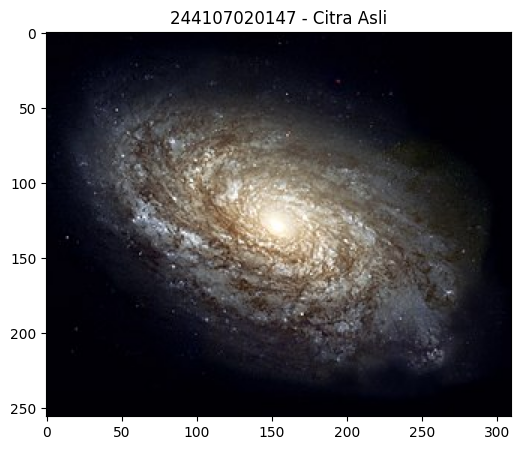

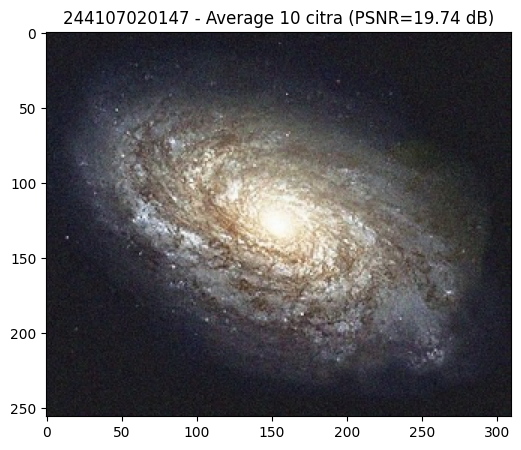

Average 10 citra -> PSNR = 19.74 dB


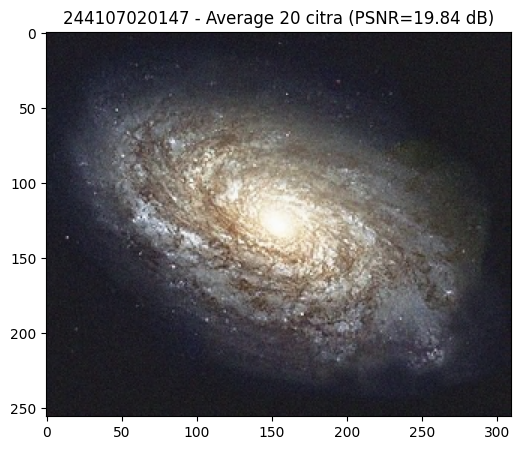

Average 20 citra -> PSNR = 19.84 dB


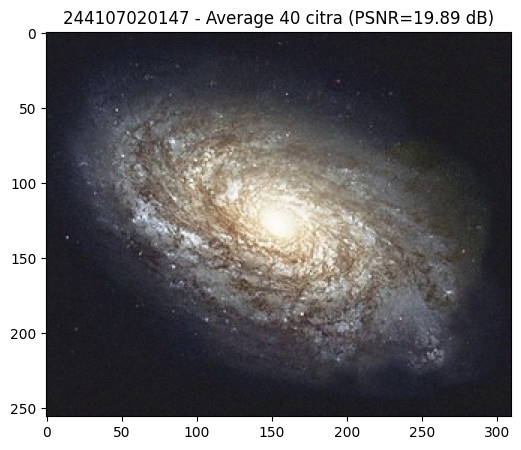

Average 40 citra -> PSNR = 19.89 dB


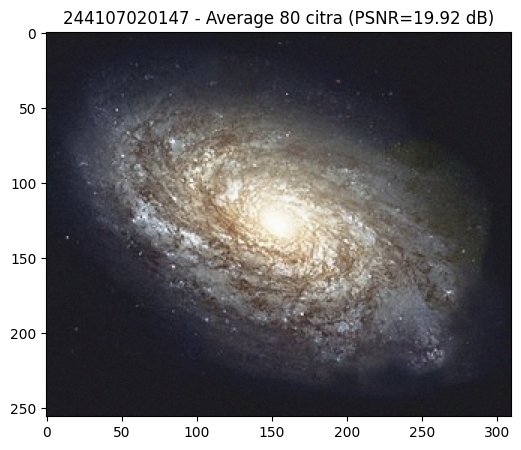

Average 80 citra -> PSNR = 19.92 dB


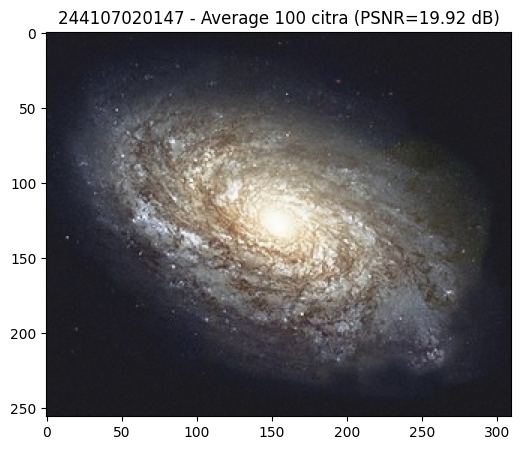

Average 100 citra -> PSNR = 19.92 dB


In [ ]:
import glob
from math import log10, sqrt

def PSNR(img1, img2):
    img1 = img1.astype(np.float64)
    img2 = img2.astype(np.float64)
    mse = np.mean((img1 - img2) ** 2)
    if mse == 0:
        return float('inf')
    return 20 * log10(255.0 / sqrt(mse))

#citra asli
galaxy = cv.imread('/content/drive/MyDrive/PCVK2026/galaxy.jpg')

#semua citra noise
cv_img = []
for img in sorted(glob.glob('/content/drive/MyDrive/PCVK2026/noises/*.jpg')):
    n = cv.imread(img)
    cv_img.append(n)

print('Jumlah citra noise terbaca:', len(cv_img))

#tampilkan citra asli
plt.figure(figsize=(6,5))
plt.imshow(cv.cvtColor(galaxy, cv.COLOR_BGR2RGB))
plt.title(NIM + ' - Citra Asli')
plt.show()

#Average 10 citra
n = 10
avg_image = np.mean(cv_img[:n], axis=0).astype(np.uint8)
psnr_val = PSNR(galaxy, avg_image)
plt.figure(figsize=(6,5))
plt.imshow(cv.cvtColor(avg_image, cv.COLOR_BGR2RGB))
plt.title(NIM + f' - Average {n} citra (PSNR={psnr_val:.2f} dB)')
plt.show()
print(f'Average {n} citra -> PSNR = {psnr_val:.2f} dB')

#Average 20 citra
n = 20
avg_image = np.mean(cv_img[:n], axis=0).astype(np.uint8)
psnr_val = PSNR(galaxy, avg_image)
plt.figure(figsize=(6,5))
plt.imshow(cv.cvtColor(avg_image, cv.COLOR_BGR2RGB))
plt.title(NIM + f' - Average {n} citra (PSNR={psnr_val:.2f} dB)')
plt.show()
print(f'Average {n} citra -> PSNR = {psnr_val:.2f} dB')

#Average 40 citra
n = 40
avg_image = np.mean(cv_img[:n], axis=0).astype(np.uint8)
psnr_val = PSNR(galaxy, avg_image)
plt.figure(figsize=(6,5))
plt.imshow(cv.cvtColor(avg_image, cv.COLOR_BGR2RGB))
plt.title(NIM + f' - Average {n} citra (PSNR={psnr_val:.2f} dB)')
plt.show()
print(f'Average {n} citra -> PSNR = {psnr_val:.2f} dB')

#Average 80 citra
n = 80
avg_image = np.mean(cv_img[:n], axis=0).astype(np.uint8)
psnr_val = PSNR(galaxy, avg_image)
plt.figure(figsize=(6,5))
plt.imshow(cv.cvtColor(avg_image, cv.COLOR_BGR2RGB))
plt.title(NIM + f' - Average {n} citra (PSNR={psnr_val:.2f} dB)')
plt.show()
print(f'Average {n} citra -> PSNR = {psnr_val:.2f} dB')

#Average 100 citra
n = 100
avg_image = np.mean(cv_img[:n], axis=0).astype(np.uint8)
psnr_val = PSNR(galaxy, avg_image)
plt.figure(figsize=(6,5))
plt.imshow(cv.cvtColor(avg_image, cv.COLOR_BGR2RGB))
plt.title(NIM + f' - Average {n} citra (PSNR={psnr_val:.2f} dB)')
plt.show()
print(f'Average {n} citra -> PSNR = {psnr_val:.2f} dB')

**Jawaban:**<br>
* Apakah peningkatan jumlah citra selalu memberikan
peningkatan PSNR yang signifikan?<br>
**Jawaban:**<br> Tidak. Peningkatan jumlah citra pada average denoising tidak selalu memberikan peningkatan PSNR yang signifikan. Berdasarkan data yang diperoleh, kenaikan PSNR terbesar terjadi pada tahap awal (10-20 citra, naik 0.10 dB), kemudian kenaikannya semakin mengecil pada tahap berikutnya (20-40 naik 0.05 dB, 40-80 naik 0.03 dB), dan pada 80-100 citra PSNR tidak lagi meningkat (tetap 19.92 dB)
* Pada jumlah citra berapa peningkatan mulai tidak terlalu signifikan?<br>
**Jawaban:**<br>
Peningkatan mulai tidak signifikan pada rentang 40 hingga 80 citra, di mana kenaikan PSNR hanya sebesar 0.03 dB, dan sepenuhnya berhenti meningkat pada rentang 80 hingga 100 citra
* Apa Kesimpulan yang
Anda peroleh dari percobaan ini?<br>
**Jawaban:**<br>
Hal ini terjadi karena secara matematis, noise pada averaging berkurang sebanding dengan 1/akar N terhadap jumlah citra N yang dirata-rata, sehingga penambahan citra memberikan manfaat yang semakin kecil seiring bertambahnya N. Berdasarkan data PSNR yang diperoleh, penambahan citra di atas 40–50 citra tidak lagi efektif secara signifikan, sehingga menambah lebih banyak citra noise (misalnya hingga 100 citra) tidak sebanding dengan biaya akuisisi dan komputasi tambahan yang dikeluarkan

9. **Buat Image Masking untuk Penyamaran Data Pribadi
Buat mask biner Anda sendiri yang menutup area foto wajah dan area NIM pada
KTM1d.jpg, lalu gabungkan dengan citra menggunakan operator AND sehingga kedua
area tersebut tersamarkan. Tuliskan koordinat kotak mask yang Anda pakai.
Lakukan percobaan menggunakan operator lain pada mask buatan Anda sendiri dan
tunjukkan hasilnya pada tabel berikut. Tuliskan analisa Anda mengapa citra keluarannya
seperti itu.**


Ukuran citra: 1280 x 809


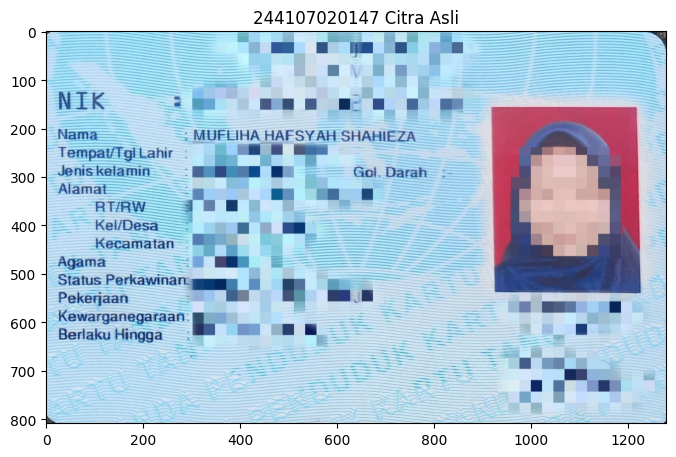

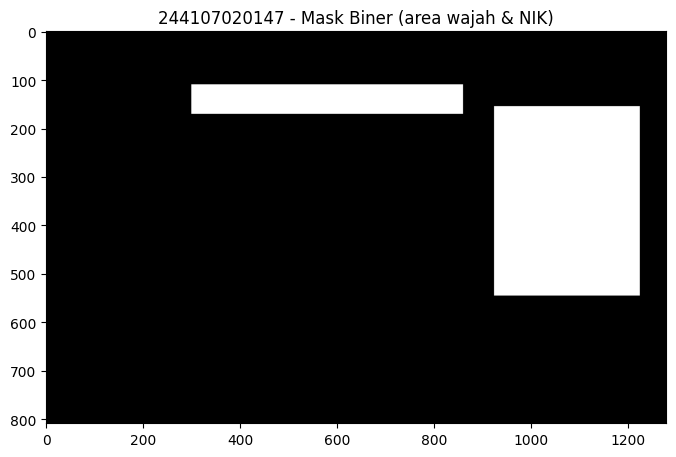

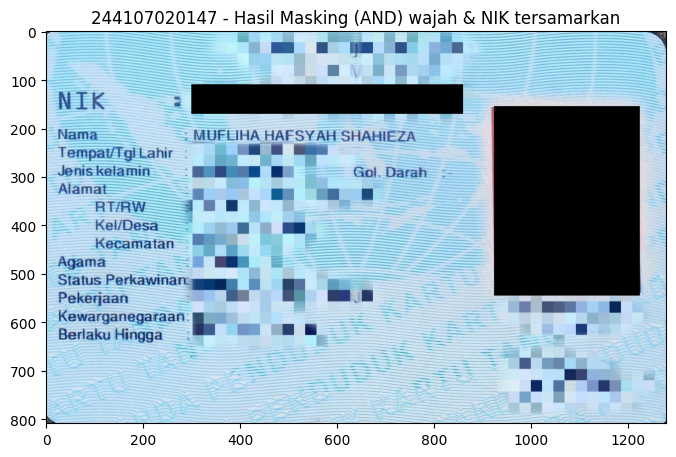

Koordinat mask wajah : (925, 155) - (1225, 545)
Koordinat mask NIK   : (300, 110), (860, 170)


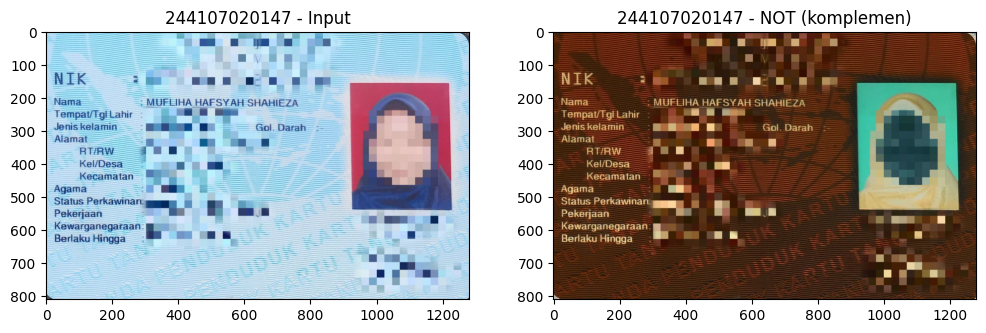

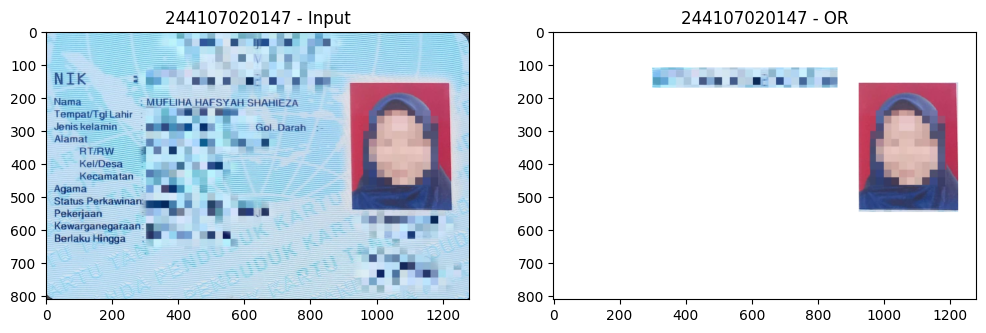

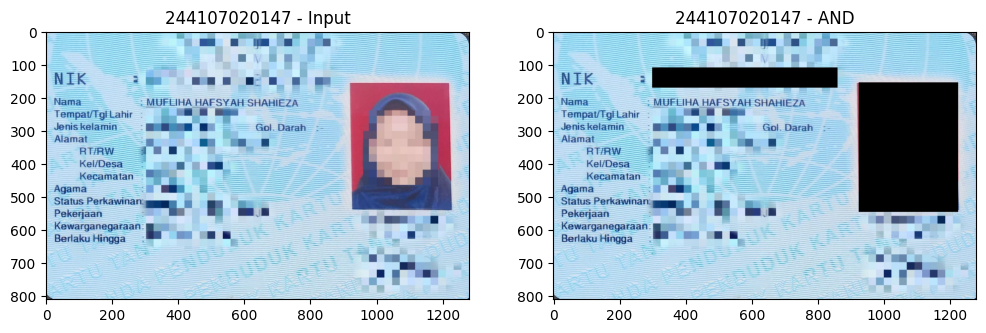

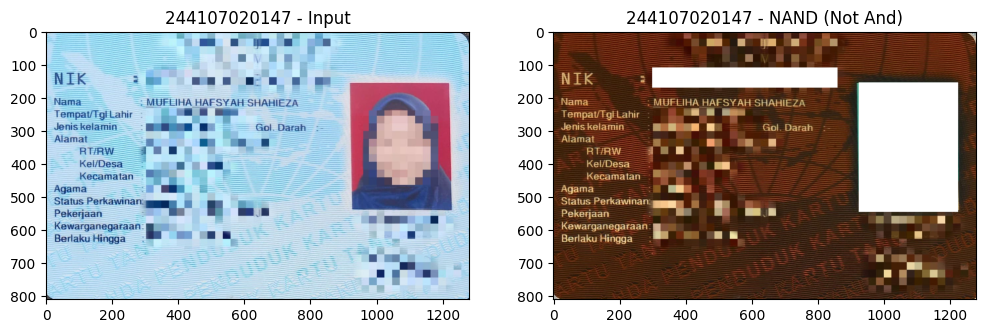

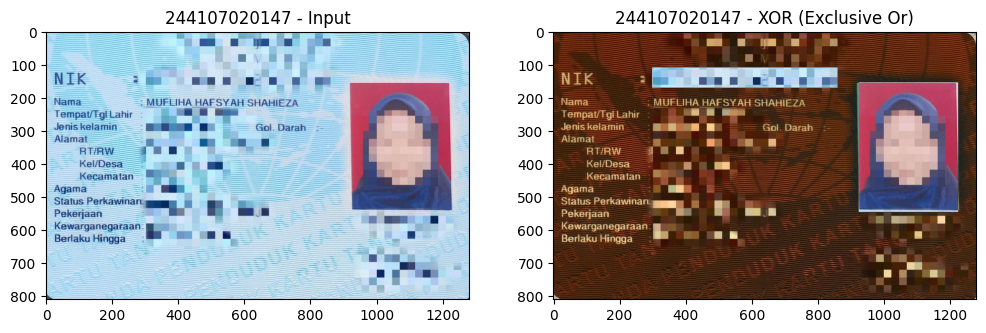

In [ ]:
KTM1d = cv.imread('/content/drive/MyDrive/PCVK2026/KTP1d.jpeg')
h, w = KTM1d.shape[:2]
print('Ukuran citra:', w, 'x', h)

#Menampilkan citra asli dulu utk menentukan koordinat area wajah & NIK
plt.figure(figsize=(8,6))
plt.imshow(cv.cvtColor(KTM1d, cv.COLOR_BGR2RGB))
plt.title(NIM + ' Citra Asli')
plt.show()

#Buat mask biner
mask = np.zeros((h, w), dtype=np.uint8)
# format: cv.rectangle(mask, (x1,y1), (x2,y2), warna, -1) -1 artinya kotak terisi penuh
cv.rectangle(mask, (925, 155), (1225, 545), 255, -1)  # area wajah
cv.rectangle(mask, (300, 110), (860, 170), 255, -1)   # area NIK

#tampilkan mask
plt.figure(figsize=(8,6))
plt.imshow(mask, cmap='gray')
plt.title(NIM + ' - Mask Biner (area wajah & NIK)')
plt.show()

#Gabungkan dengan operator AND untuk menyamarkan, menggunakan invers mask
mask_inv = cv.bitwise_not(mask)
mask_inv_3ch = cv.cvtColor(mask_inv, cv.COLOR_GRAY2BGR)

result_and = cv.bitwise_and(KTM1d, mask_inv_3ch)

plt.figure(figsize=(8,6))
plt.imshow(cv.cvtColor(result_and, cv.COLOR_BGR2RGB))
plt.title(NIM + ' - Hasil Masking (AND) wajah & NIK tersamarkan')
plt.show()

print('Koordinat mask wajah : (925, 155) - (1225, 545)')
print('Koordinat mask NIK   : (300, 110), (860, 170)')

def tampilkan_perbandingan(img_input, img_output, judul):
    plt.figure(figsize=(12,6))

    plt.subplot(1, 2, 1)
    plt.imshow(cv.cvtColor(img_input, cv.COLOR_BGR2RGB))
    plt.title(NIM + ' - Input')

    plt.subplot(1, 2, 2)
    plt.imshow(cv.cvtColor(img_output, cv.COLOR_BGR2RGB))
    plt.title(NIM + ' - ' + judul)

    plt.show()

#Percobaan operator logika lain
# 1. NOT (komplemen)
result_not = cv.bitwise_not(KTM1d)
tampilkan_perbandingan(KTM1d, result_not, 'NOT (komplemen)')

# 2. OR - citra asli OR mask
result_or = cv.bitwise_or(KTM1d, mask_inv_3ch)
tampilkan_perbandingan(KTM1d, result_or, 'OR')

# 3. AND
tampilkan_perbandingan(KTM1d, result_and, 'AND')

# 4. NAND (Not AND)
result_nand = cv.bitwise_not(cv.bitwise_and(KTM1d, mask_inv_3ch))
tampilkan_perbandingan(KTM1d, result_nand, 'NAND (Not And)')

# 5. XOR (Exclusive Or)
result_xor = cv.bitwise_xor(KTM1d, mask_inv_3ch)
tampilkan_perbandingan(KTM1d, result_xor, 'XOR (Exclusive Or)')

**Jawaban:** <br>
* Operator NOT diterapkan pada seluruh citra (bukan hanya area mask), sehingga semua piksel dibalik nilainya (255 - x). Hasilnya seluruh citra menjadi "negatif" dan warnanya terbalik, namun pola wajah & teks NIK tetap bisa dikenali, hanya berubah warna.
* Operator OR menghasilkan kebalikannya: area di luar mask (mask_inv = 255) dipaksa menjadi putih (x OR 255 = 255), sedangkan area wajah & NIK (mask_inv = 0) justru x OR 0 = x, artinya data aslinya tetap terlihat utuh, tidak tersamarkan.
* Operator AND antara citra asli dengan mask_inv menghasilkan x AND 0 = 0 pada area wajah & NIK (karena mask_inv bernilai 0 di situ), sehingga kedua area tersebut berubah hitam pekat, sedangkan area lain (x AND 255 = x) tetap tampil apa adanya. Operator ini cocok untuk menyamarkan data.
* Operator NAND adalah komplemen dari AND, sehingga area yang pada AND berwarna hitam (wajah & NIK) berbalik menjadi putih polos, sedangkan area lain menjadi negatif dari citra asli. Area sensitif jadi "disorot" putih, bukan disembunyikan.
* Operator XOR menghasilkan nilai tinggi hanya pada piksel yang berbeda dari mask, sehingga area wajah & NIK justru tampak sebagai pola kontras/highlight (bukan blok solid), dan sebagian informasi asli citra masih tercampur di dalamnya.

Jadi, dapat diambil kesimpulan bahwa hanya operator AND yang cocok untuk penyamaran data, karena sifatnya "menghilangkan" nilai piksel (menjadi 0/hitam) tepat pada area mask tanpa mengubah area lain. Operator lain (NOT, OR, NAND, XOR) tidak cocok karena masing-masing justru membalik, mempertahankan, atau mencampur nilai piksel asli, sehingga area sensitif tetap bisa dikenali atau malah lebih menonjol.

10. **Foto Malam Hari
Carilah foto malam hari yang gelap. Namun, beberapa bagian gambar memiliki detail yang
sebenarnya cukup baik. Pilih salah satu metode berikut dan implementasikan pada foto
tersebut (Linear Brightness, Contrast, Logarithmic Brightness, Gamma Correction). Sebutkan
alasan dan resiko metode yang Anda gunakan.**<br>

**Perbaiki kualitas pada citra tersebut dengan metode operasi dasar citra apapun.
Diperbolehkan menggunakan lebih dari 1 metode. Kemudian jelaskan:**
* **Metode yang dipilih**
* **Alasan pemilihan**
* **Menentukan parameter terbaik**
* **Menghasilkan citra dengan menunjukkan before-after.**

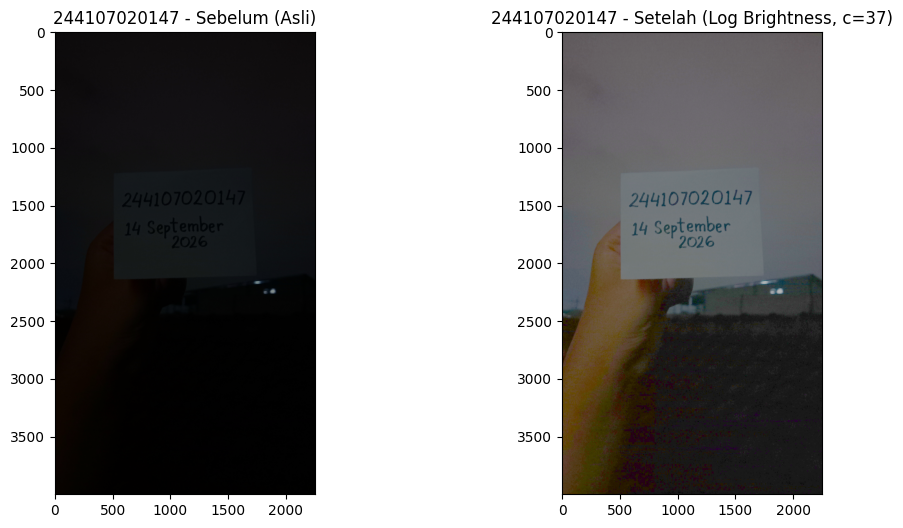

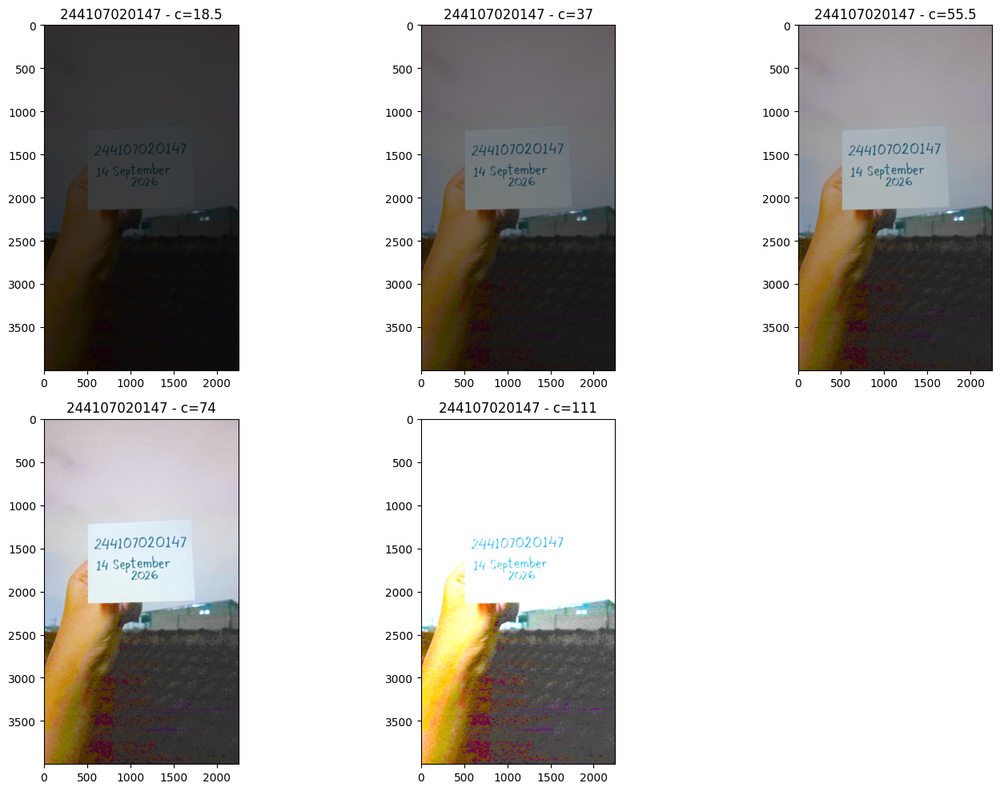

In [ ]:
NIGHT1 = cv.imread('/content/drive/MyDrive/PCVK2026/NIGHT1.jpg')

img_float = NIGHT1.astype(np.float64)

#Log Brightness s = c * log(1 + r)
c = PARAM['c']

result_log = c * np.log1p(img_float)
result_log = np.clip(result_log, 0, 255).astype(np.uint8)

#Tampilkan before-after
plt.figure(figsize=(12,6))

plt.subplot(1, 2, 1)
plt.imshow(cv.cvtColor(NIGHT1, cv.COLOR_BGR2RGB))
plt.title(NIM + ' - Sebelum (Asli)')

plt.subplot(1, 2, 2)
plt.imshow(cv.cvtColor(result_log, cv.COLOR_BGR2RGB))
plt.title(NIM + ' - Setelah (Log Brightness, c=' + str(c) + ')')

plt.show()

#Mencoba beberapa nilai c untuk mencari parameter terbaik
nilai_c_dicoba = [PARAM['c']*0.5, PARAM['c'], PARAM['c']*1.5, PARAM['c']*2, PARAM['c']*3]

plt.figure(figsize=(15,10))
for i, c_val in enumerate(nilai_c_dicoba):
    hasil = c_val * np.log1p(img_float)
    hasil = np.clip(hasil, 0, 255).astype(np.uint8)

    plt.subplot(2, 3, i+1)
    plt.imshow(cv.cvtColor(hasil, cv.COLOR_BGR2RGB))
    plt.title(NIM + ' - c=' + str(round(c_val,1)))

plt.tight_layout()
plt.show()

**Jawaban:** <br>
* Metode yang dipilih adalah Logarithmic Brightness, karena foto NIGHT1 memiliki background nyaris hitam pekat, sementara kertas berisi NIM & tanggal sudah cukup terang. Transformasi log cocok untuk kasus ini karena menaikkan nilai piksel gelap secara nonlinear (kenaikan besar di area gelap, kenaikan kecil di area yang sudah terang), sehingga detail background bisa terangkat tanpa langsung membuat kertas clipping ke putih polos.
* Dari percobaan 5 nilai c (18.5, 37, 55.5, 74, 111), nilai c yang terlalu kecil (18.5–37) belum cukup mengangkat detail background, sedangkan nilai c yang terlalu besar (74–111) menimbulkan noise warna (bintik pink/ungu) yang semakin banyak dan membuat area terang (langit, kertas) mulai overexposed.
* Parameter terbaik yang dipilih yaitu c = 55.5, karena pada nilai ini detail background (atap rumah, bangunan, langit) sudah terlihat jelas, tulisan pada kertas (NIM & tanggal) masih tajam dan terbaca, sementara noise warna belum terlalu mengganggu dibanding c=74 dan c=111.
* Risiko menggunakan metode ini adalah pada nilai c yang lebih besar, noise pada area gelap ikut terangkat dan semakin terlihat (grain/bintik warna), serta area yang sudah terang berisiko clipping/overexposed sehingga detail justru menghilang.